# Exercise: From Energy to Speed in a 2D Gas

**Background:**
Consider a classical ideal gas confined to two dimensions. According to Boltzmann statistics, the dimensionless kinetic energy $x$ of a single particle follows an exponential probability density function (PDF) for $x \geq 0$:
$$f(x) = e^{-x}$$

We want to determine the statistical properties of the particle's dimensionless speed, defined as:
$$y = \sqrt{x}$$

In this exercise, you will first derive the exact statistical properties of the speed analytically, and then verify your results using Monte Carlo sampling.

## Part 1: Analytical Derivations

Using exact mathematical methods, solve the following:
1. **The PDF:** Use the transformation of variables formula to derive the analytical PDF for the speed, $g(y)$.

2. **The Median:** Find the median speed $y_{med}$, defined as the value where the CDF $G(y_{med}) = 0.5$. (*Bonus: is there an easier way to get the median of the derived function?*)

3. **The Expectation Value:** Calculate the expected value (mean) of the speed, $E[y]$.
   
   *(Hint: You may use the standard Gaussian integral $\int_0^\infty e^{-u^2} du = \frac{\sqrt{\pi}}{2}$)*.

4. **The Variance:** Calculate the variance of the speed, $V[y] = E[y^2] - (E[y])^2$.

## Part 2: Monte Carlo Simulation

Now, use Monte Carlo sampling to verify your analytical results.
1. **Generate** $N = 10^6$ random samples of the energy $x$ drawn from the exponential distribution $f(x)$.
2. **Transform** these samples to get an array of simulated speeds, $y = \sqrt{x}$.
3. **Calculate** the sample mean, sample variance, and sample median of $y$.
4. **Plot** a normalized histogram of your simulated $y$ samples and overlay your analytical PDF $g(y)$.

## Part 3: Discussion

**Question:** Compare your analytical results from Part 1 with the Monte Carlo numerical estimates from Part 2. Do they agree?

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
def kenergy_pdf(x):
    return np.exp(-x)
def speed_pdf(x):
    return 2*x*np.exp(-x**2)
def speed_cdf(x):
    return 1 - np.exp(-x**2)

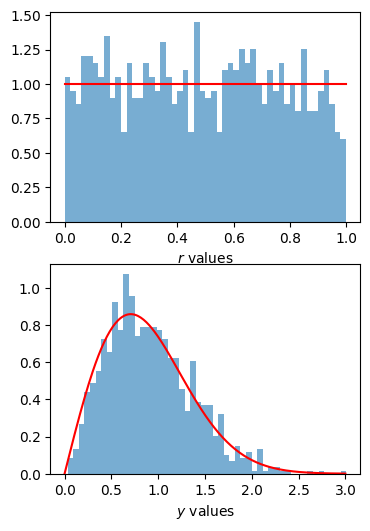

In [ ]:
r = np.random.uniform(size=1000)

# correct transformation
y = np.sqrt(-np.log(r))

fig, ax = plt.subplots(2,1,figsize=(4,6))

# Uniform distribution
ax[0].hist(r, bins=50, density=True, alpha=0.6)
ax[0].plot([0,1],[1,1],'r')
ax[0].set_xlabel('$r$ values')

# Speed distribution
ax[1].hist(y, bins=50, density=True, alpha=0.6)

t = np.linspace(0,3,200)
ax[1].plot(t, speed_pdf(t),'r')

ax[1].set_xlabel('$y$ values')

plt.show()

In [ ]:
median = np.sqrt(-np.log(0.5))
print('median:', median)
mean = np.mean(y)
print('mean:', mean)
variance = np.var(y)
print('variance:',variance)

median: 0.8325546111576977
mean: 0.9095071735833833
variance: 0.2106555394160544
